In [1]:
import os, glob, json
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 40); pd.set_option("display.max_colwidth", 60)
plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.25})

V4 = os.path.abspath("../../../wildfire-datasets-v4")     # the dataset folder (sits next to wildfire-ml-v4)
DS = V4 + "/dataset"                                       # built datasets
RAW = V4 + "/inputs_raw"                                   # raw downloads, exactly as they arrived
START = pd.Timestamp("2019-01-01")                         # day 0 of the cube; day t = START + t days

# 08. Weather forecast inputs (GFS)

**Why add it?** All our weather channels describe **today** (or earlier). The label is about **tomorrow**. A forecast of tomorrow's weather (wind, heat, dryness, rain)
is something a real forecaster would use, and the live demo will need exactly this kind of data.

**Source:** NOAA's GFS model, 0.25 degree (about 25 km), through the NCAR data archive (RDA, dataset ds084.1). The same product is available live from NOAA, so the demo can use the same kind of number.

**Rule so we do not cheat:** for day `d` we use the forecast **issued at 06:00 UTC on day d**, for the hours that fall on **day d + 1**. Anything newer than that would not exist at prediction time.

## 1. What we asked the archive for

In [2]:
products = ["2 m temperature", "2 m dewpoint", "10 m wind (u and v)", "wind gust", "soil water, 0 to 10 cm", "precipitation rate (6-hour average)"]
print("request: forecast hours 18 to 42 after the 06 UTC run, every 3 hours, for the box lat 6 to 36, lon 68 to 98")
print("fields :", ", ".join(products))
print("one monthly request is a ~350 MB tar of GRIB2 files; we read it in memory, keep the 06 UTC files, interpolate to our cell centres, and delete the tar.")

request: forecast hours 18 to 42 after the 06 UTC run, every 3 hours, for the box lat 6 to 36, lon 68 to 98
fields : 2 m temperature, 2 m dewpoint, 10 m wind (u and v), wind gust, soil water, 0 to 10 cm, precipitation rate (6-hour average)
one monthly request is a ~350 MB tar of GRIB2 files; we read it in memory, keep the 06 UTC files, interpolate to our cell centres, and delete the tar.


## 2. What we keep: 8 channels per cell and day

In [3]:
GFS = RAW + "/gfs_rda/months"
files = sorted(glob.glob(GFS + "/gfs_*.npz"))
z = np.load(files[0], allow_pickle=True)
print("one monthly file:", os.path.basename(files[0]), " data shape [days, cells, channels] =", z["data"].shape)
print("channels:", [str(n) for n in z["names"]])

one monthly file: gfs_201901.npz  data shape [days, cells, channels] = (31, 7674, 8)
channels: ['gfs_t2m_max', 'gfs_t2m_mean', 'gfs_rh_min', 'gfs_vpd_max', 'gfs_wind_mean', 'gfs_gust_max', 'gfs_rain_mm', 'gfs_soil_0_10']


| channel | meaning (tomorrow, 24 hours from 18 to 42 hours after the run) |
|---|---|
| `gfs_t2m_max`, `gfs_t2m_mean` | hottest and average temperature |
| `gfs_rh_min` | driest relative humidity of the day |
| `gfs_vpd_max` | highest vapour pressure deficit |
| `gfs_wind_mean`, `gfs_gust_max` | average wind speed and strongest gust |
| `gfs_rain_mm` | total rain of the day |
| `gfs_soil_0_10` | soil water in the top 10 cm |

Notice the GFS gives **hourly (3-hourly) values**, so the humidity and gust are the real driest hour and the strongest gust. ERA5-Land only gave a daily mean, which is why its humidity is a proxy.

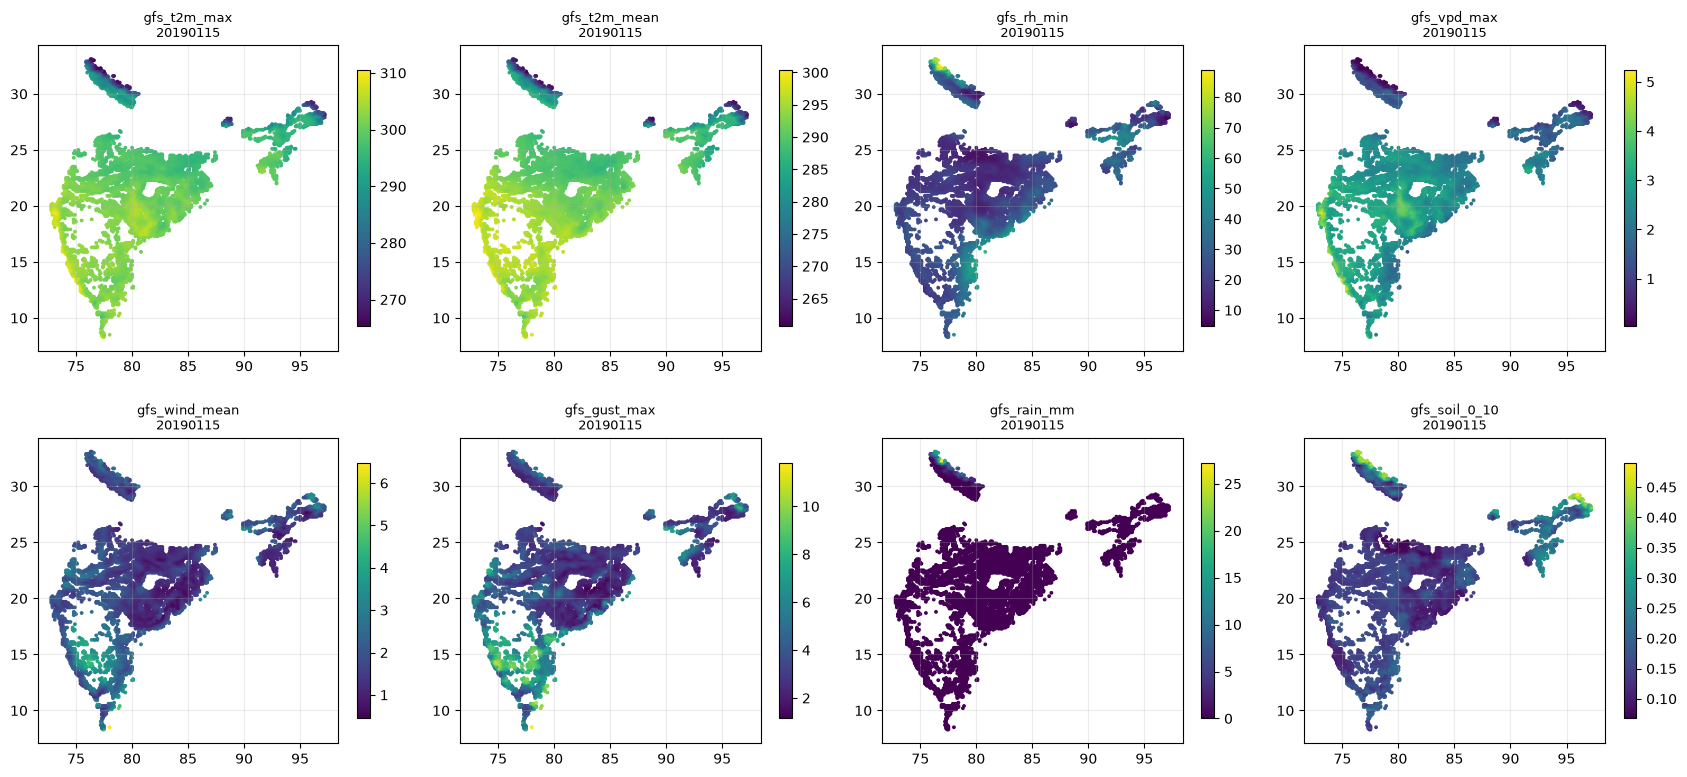

In [4]:
cells = pd.read_parquet(f"{DS}/forest_all/cells.parquet")
d = z["data"][14, :len(cells)]                 # one day, only the 7,148 training cells
names8 = [str(n) for n in z["names"]]
fig, ax = plt.subplots(2, 4, figsize=(17, 8))
for a, k in zip(ax.ravel(), range(8)):
    sc = a.scatter(cells.lon, cells.lat, c=d[:, k], s=3, cmap="viridis"); plt.colorbar(sc, ax=a, shrink=0.7); a.set_title(names8[k] + f"\n{int(z['days'][14])}", fontsize=9); a.set_aspect("equal")
plt.tight_layout(); plt.show()

## 3. What is on disk right now

In [5]:
have = {os.path.basename(f)[4:10] for f in files}
want = [f"{y}{m:02d}" for y in range(2019, 2026) for m in range(1, 13)]
grid = pd.DataFrame([[("x" if f"{y}{m:02d}" in have else ".") for m in range(1, 13)] for y in range(2019, 2026)], index=range(2019, 2026), columns=range(1, 13))
print(len(have), "of", len(want), "months on disk  (x = have, . = not yet).  The full download is running in the background.")
grid

23 of 84 months on disk  (x = have, . = not yet).  The full download is running in the background.


,1,2,3,4,5,6,7,8,9,10,11,12
2019,x,x,x,x,x,x,x,x,x,x,x,x
2020,.,.,.,.,.,.,.,.,.,.,.,.
2021,.,.,.,.,.,x,.,.,.,.,.,.
2022,x,x,x,x,x,.,.,.,.,.,.,.
2023,x,x,x,x,x,.,.,.,.,.,.,.
2024,.,.,.,.,.,.,.,.,.,.,.,.
2025,.,.,.,.,.,.,.,.,.,.,.,.


## 4. Does the forecast agree with the weather we already have?

March 2022, GFS forecast of tomorrow vs ERA5-Land tomorrow, hottest temperature:
  correlation 0.971   mean difference (GFS - ERA5) 2.37 K


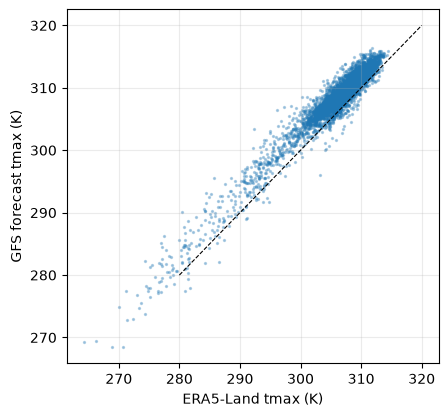

In [6]:
import sys; sys.path.insert(0, os.path.abspath("../.."))
from src import data
ds = data.load_train(); names = [str(n) for n in np.load(f"{DS}/scaler_forest_A_train.npz", allow_pickle=True)["names"]]
zz = np.load(GFS + "/gfs_202203.npz", allow_pickle=True); n = len(cells)
t0 = (pd.Timestamp("2022-03-01") - START).days
era_tmax = np.asarray(ds.cube[t0 + 1:t0 + 31, :, names.index("t2m_max")])         # ERA5-Land, day d + 1  (the forecast for d + 1 is stored on day d)
gfs_tmax = zz["data"][:30, :n, 0]
ok = ~np.isnan(gfs_tmax) & ~np.isnan(era_tmax)
print("March 2022, GFS forecast of tomorrow vs ERA5-Land tomorrow, hottest temperature:")
print("  correlation", round(float(np.corrcoef(gfs_tmax[ok], era_tmax[ok])[0, 1]), 3), "  mean difference (GFS - ERA5)", round(float((gfs_tmax[ok] - era_tmax[ok]).mean()), 2), "K")
plt.figure(figsize=(4.8, 4.6)); plt.scatter(era_tmax[ok][::50], gfs_tmax[ok][::50], s=2, alpha=0.3); plt.plot([280, 320], [280, 320], "k--", lw=0.8); plt.xlabel("ERA5-Land tmax (K)"); plt.ylabel("GFS forecast tmax (K)"); plt.show()

## 5. What happened when we gave it to the models

On a small test (January to May 2022 for training, January to May 2023 for validation, about 1 million rows):

- **XGBoost:** AUPRC went from 0.430 to 0.452 (+0.021). The paired 95% interval is 0.006 to 0.041, so it is above zero. On rows with no fire today the gain is +0.017 (0.005 to 0.033).
- **Graph model (C2), 100,000-row sample, three seeds:** 0.448 to 0.466.
- **ConvLSTM, same sample:** 0.427 to 0.443.

The size of the gain is similar in all three models. These are validation numbers only, nothing from the test year.

## 6. What is missing or weak here

- **Only a few months are on disk so far.** The rest of 2019 to 2025 is downloading. A run with GFS needs every day filled.
- **GFS changed its model around March 2021** (an upgrade). Forecast skill may jump at that date. We have not yet checked it; the downloaded 2019 to 2021 months will let us look.
- **Forecast, not truth.** The forecast has errors, and rain is the hardest. The live demo uses the same kind of forecast, so training on forecasts and not on truth is the right match.
- **25 km grid.** Coarser than our 11 km cells. Neighbouring cells share the same forecast values.
- **One run per day (06 UTC).** We do not use newer runs, because training and the live system must use the same rule.